# SymPhase tutorial 12 — magnetic supercells: multi-Q, conical and distorted spirals

The rotating frame (tutorial 10) treats **one planar spiral** in a Hamiltonian invariant about the spiral axis, without a supercell.
Everything else needs an explicit magnetic supercell:

| state | breaks the rotating frame because … | example |
|---|---|---|
| conical spiral | uniform component along the axis (field) | `Conical_J1J2_field` |
| distorted spiral | in-plane anisotropy → harmonics 3q, 5q | `Distorted_spiral_K` |
| multi-Q / skyrmion crystal | several Q at once, DM vectors in several directions | `Skyrmion_triangular` |

`symphase magnons ... --supercell auto` runs the complete workflow (full step-by-step guide: `docs/SUPERCELL_WORKFLOW.md`):

1. **Luttinger–Tisza** scan → ordering vector $q_{LT}$ and its star;
2. **supercell size** from commensurate approximants of all star members;
3. exact **mapping** of exchange, anisotropy and field onto the supercell;
4. **classical relaxation** (L-BFGS) from many seeds: input state, ferromagnet, single-Q / conical / multi-Q seeds built from the LT eigenvectors, random states;
5. **identification**: structure factor, harmonics, uniform weight, topological charge;
6. **spin waves** in the supercell (stability, Goldstone modes, folded bands);
7. **files** for DFT and for the symmetry analysis of the new state.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import numpy as np, spglib, math
import matplotlib.pyplot as plt
from symphase.magnons import analyse, read_exchange_file, plot_bands
from symphase.tensors import read_poscar
from symphase.supercell import run_supercell, scan_sizes, report, plot_state, write_outputs
a = 3.0
lat, fr = np.diag([a, 12, 12]), np.zeros((1, 3))          # 1D chain, one Fe per cell
ds = spglib.get_symmetry_dataset((lat, fr, [0])); m0 = np.array([[0, 0, 2.0]])
def chain(size="auto", J=(-1.0, 0.5), **kw):
    base = dict(J=list(J), spin=1.0, rmax=6.1, restarts=3, spectrum=False); base.update(kw)
    return run_supercell(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, size=size, **base)
sk = f"{EX}/vasp/Skyrmion_triangular"
ps = read_poscar(f"{sk}/POSCAR"); dss = spglib.get_symmetry_dataset((ps["lattice"], ps["frac"], [0]))
exs = read_exchange_file(f"{sk}/J_DMI.dat")
def skx(B, size=(10, 10, 1), **kw):
    base = dict(restarts=2, spectrum=False); base.update(kw)
    return run_supercell(ps["lattice"], ps["frac"], [0], ["Mn"], np.array([[0, 0, 2.0]]), dss.rotations,
                         dss.translations, size=list(size) if size != "auto" else "auto", exchange=exs, spin=1.0,
                         rmax=3.1, field=[0, 0, B], **base)

## 1. Sanity check: the J₁–J₂ chain needs 6 cells

$J_1=-1$, $J_2=0.5$ meV: $q=1/6$ exactly. The automatic size search must find 6 cells and the rotating-frame energy −0.75 meV.

In [3]:
r = chain()
report(r, ["Fe"])
print("\nsupercell:", np.diag(r["M"]), "  E/cell =", round(r["E_cell"], 8))


  ── supercell workflow (multi-Q / conical / distorted states) ──
  1. Luttinger–Tisza minimum: q_LT = [0.16667 0.      0.     ] r.l.u.  (λ = -0.75000 meV, λ(q=0) = -0.50000);  star: 1 member(s)
       q1 = [0.16667 0.      0.     ]
  2. supercell search (penalty = LT energy cost of the best commensurate q, relative units):
       (1, 1, 1)        1 cells   penalty   1.00000
       (2, 1, 1)        2 cells   penalty   1.00000
       (3, 1, 1)        3 cells   penalty   1.00000
       (4, 1, 1)        4 cells   penalty   1.00000
       (5, 1, 1)        5 cells   penalty   0.14590
       (6, 1, 1)        6 cells   penalty   0.00000
     supercell M = [[6, 0, 0], [0, 1, 0], [0, 0, 1]]  (6 primitive cells, 6 magnetic sites)
  3. model mapped: 12 bonds, anisotropy no, field no
  4. 11 seeds relaxed (L-BFGS); lowest energies per primitive cell:
            -0.750000 meV   conical q1, m∥ = 0.3
            -0.750000 meV   random 1
            -0.750000 meV   random 2
            -0.750000 meV

## 2. Incommensurate $q$: converge the supercell size

For $J_2=0.4$ the exact $q=\arccos(1/1.6)/2\pi=0.14255$ is not a simple fraction. A supercell of $n$ cells allows only $q=m/n$;
the energy per cell is **not monotonic** in $n$ — it is lowest when $m/n$ is closest to $q$.

best n = 7  E = -0.712498  exact -0.7125


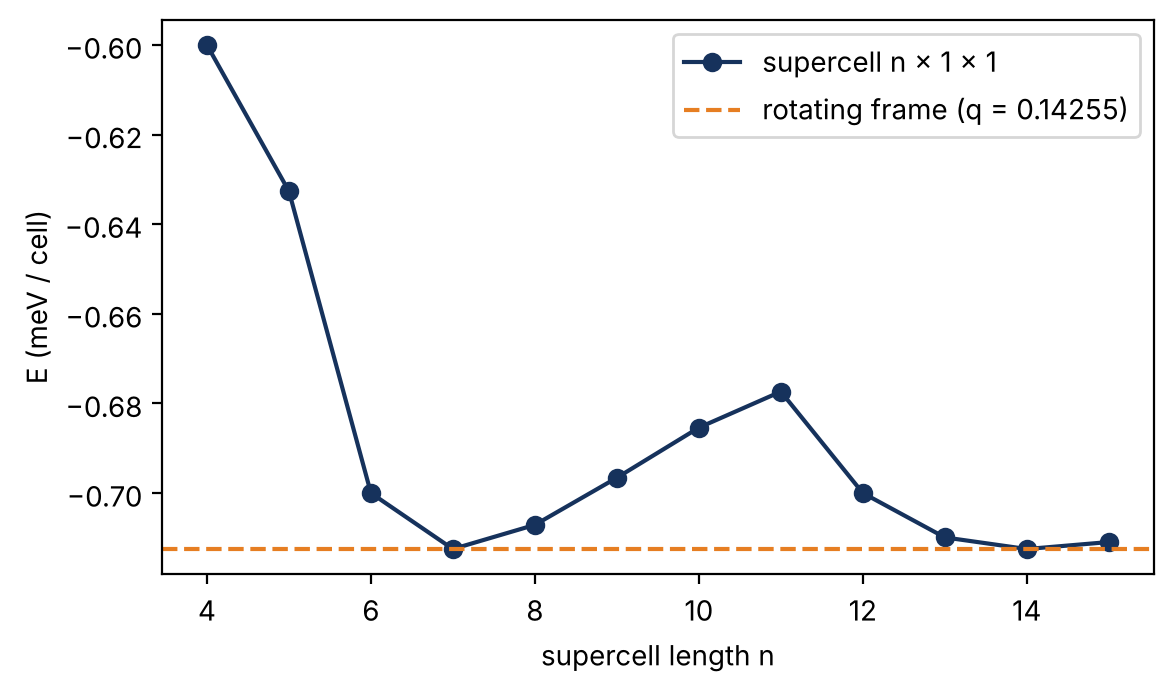

In [4]:
exact = analyse(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, J=[-1.0, 0.4], spin=1.0, rmax=6.1,
                spiral="auto", spiral_axis=[0, 0, 1], n_per=4, nmap=3)["spiral"]
rows = scan_sizes(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, [[n, 1, 1] for n in range(4, 16)],
                  restarts=3, J=[-1.0, 0.4], spin=1.0, rmax=6.1)
ns = [r_["size"][0] for r_ in rows]; Es = [r_["E_cell"] for r_ in rows]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(ns, Es, "o-", color="#16325c", label="supercell n × 1 × 1")
ax.axhline(exact["E_spiral"], color="#e67e22", ls="--", label=f"rotating frame (q = {abs(exact['q_rlu'][0]):.5f})")
ax.set_xlabel("supercell length n"); ax.set_ylabel("E (meV / cell)"); ax.legend()
best = min(rows, key=lambda r_: (round(r_["E_cell"], 9), r_["n_cells"]))
print("best n =", best["size"][0], " E =", round(best["E_cell"], 6), " exact", exact["E_spiral"])

## 3. Conical spiral in a magnetic field

A field $\mathbf B\parallel\hat z$ cants the spins out of the spiral plane. Classically $\cos\theta = g\mu_B B / \bigl(2S(J(0)-J(Q))\bigr)$
— SymPhase reproduces it exactly, and identifies the state from the structure factor (uniform weight $w(0)=\cos^2\theta$).

conical spiral (uniform component + single Q)   w(0) = 0.2144   Goldstone modes: 1


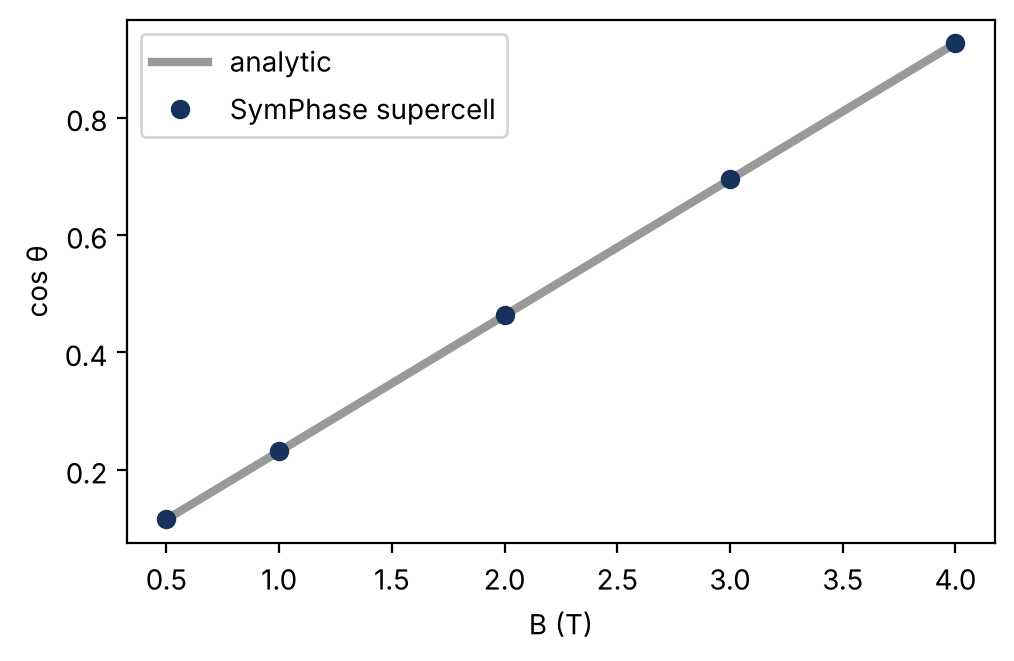

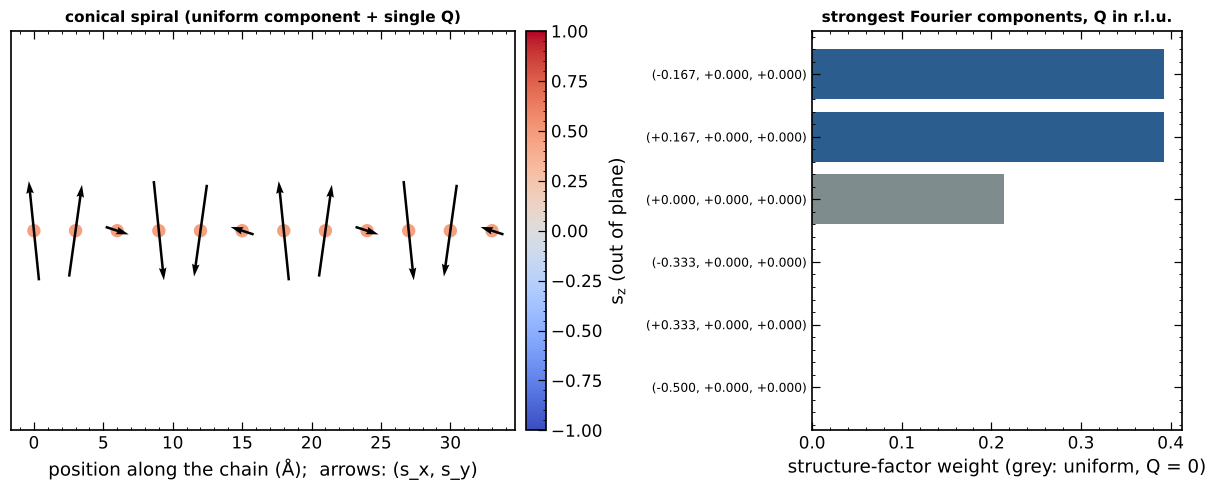

In [5]:
MUB = 0.05788381806
Bs = [0.5, 1, 2, 3, 4]
cs = [chain(field=[0, 0, B])["best"]["dirs"][:, 2].mean() for B in Bs]
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(Bs, [2 * MUB * B / 0.5 for B in Bs], color="0.6", lw=3, label="analytic")
ax.plot(Bs, cs, "o", color="#16325c", label="SymPhase supercell")
ax.set_xlabel("B (T)"); ax.set_ylabel("cos θ"); ax.legend()
rc = chain(field=[0, 0, 2.0], spectrum=True, n_per=30, nmap=5)
print(rc["character"]["cls"], "  w(0) =", round(rc["character"]["w0"], 4), "  Goldstone modes:", rc["lswt"]["n_goldstone"])
plot_state(rc);

Spin waves of the cone in the 6-cell supercell (bands are **folded**: 6 cells × 1 atom = 6 bands; one Goldstone mode = rotation about $\mathbf B$):

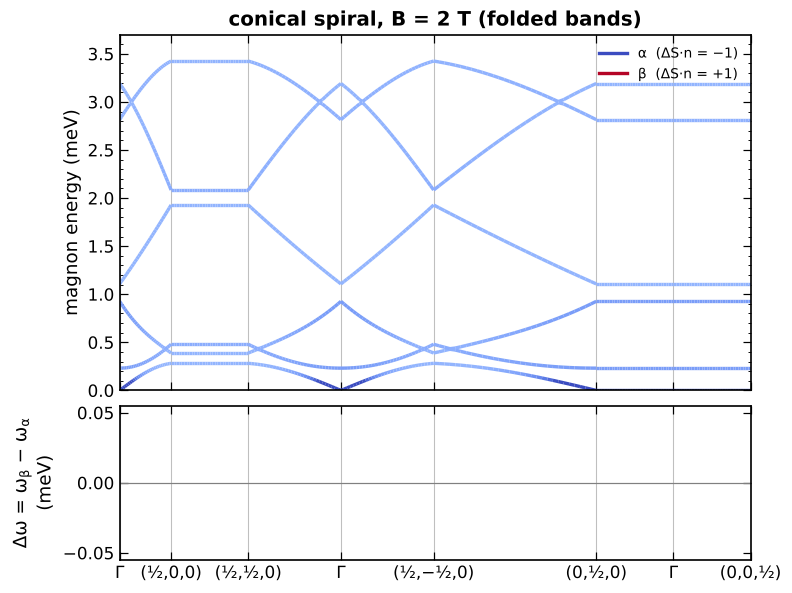

In [6]:
plot_bands(dict(rc["lswt"], spiral=None), title="conical spiral, B = 2 T (folded bands)");

## 4. Spiral distorted by an in-plane easy axis

An easy axis $K$ along $x$ (inside the spiral plane) breaks the rotation symmetry: the spins bunch near $\pm x$, the energy drops below the
undistorted spiral ($-0.75-KS^2/2$), and odd harmonics appear in the structure factor.

K = 0.1:  E = -0.801190  (undistorted -0.800000)   3q weight = 0.0006   distorted single-Q spiral (harmonics 3q; weight 0.00057)
K = 0.2:  E = -0.855128  (undistorted -0.850000)   3q weight = 0.0026   distorted single-Q spiral (harmonics 3q; weight 0.0026)
K = 0.4:  E = -0.974242  (undistorted -0.950000)   3q weight = 0.0147   distorted single-Q spiral (harmonics 3q; weight 0.015)
K = 0.6:  E = -1.116667  (undistorted -1.050000)   3q weight = 0.0494   distorted single-Q spiral (harmonics 3q; weight 0.049)


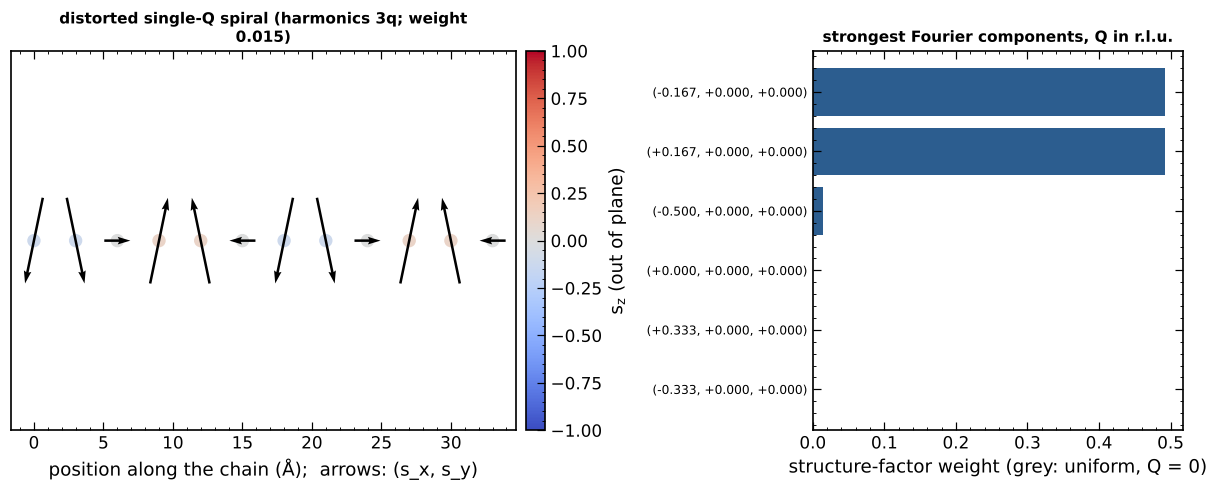

In [7]:
Ks = [0.1, 0.2, 0.4, 0.6]
res = [chain(size=[6, 1, 1], K=K, K_axis=[1, 0, 0]) for K in Ks]
for K, r_ in zip(Ks, res):
    h3 = sum(w for _, w, n in r_["character"]["harmonics"] if abs(n) == 3)
    print(f"K = {K}:  E = {r_['E_cell']:.6f}  (undistorted {-0.75 - K / 2:.6f})   3q weight = {h3:.4f}   {r_['character']['cls']}")
plot_state(res[2]);

Should the period change? Scan the size — for $K=0.4$ the 6-cell period stays lowest (lock-in):

In [8]:
for r_ in scan_sizes(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, [[n, 1, 1] for n in range(4, 10)],
                    restarts=3, J=[-1.0, 0.5], spin=1.0, rmax=6.1, K=0.4, K_axis=[1, 0, 0]):
    print(r_["size"], round(r_["E_cell"], 6), r_["cls"])

(4, 1, 1) -0.9 collinear modulated (single Q)
(5, 1, 1) -0.941449 distorted single-Q spiral (harmonics 2q; weight 0.023)
(6, 1, 1) -0.974242 distorted single-Q spiral (harmonics 3q; weight 0.015)
(7, 1, 1) -0.95799 distorted single-Q spiral (harmonics 2q, 3q; weight 0.021)
(8, 1, 1) -0.940013 distorted single-Q spiral (harmonics 3q; weight 0.031)
(9, 1, 1) -0.932981 fan / canted spiral (uniform component + single Q, coplanar)


## 5. Multi-Q: a skyrmion crystal on the triangular lattice

Ferromagnetic $J=-1$ meV, interfacial DMI $\mathbf D_{ij}=D\,\hat z\times\hat r_{ij}$ with $D=1.8$ meV, field along $z$.
The LT star has **three** members at 120°, so the supercell must be $n\times n$ (a strip cannot hold a triple-Q state).


  ── supercell workflow (multi-Q / conical / distorted states) ──
  1. Luttinger–Tisza minimum: q_LT = [-0.09251 -0.09251  0.     ] r.l.u.  (λ = -4.70896 meV, λ(q=0) = -3.00000);  star: 3 member(s)
       q1 = [-0.09251 -0.09251  0.     ]
       q2 = [ 0.09251 -0.18502  0.     ]
       q3 = [ 0.18502 -0.09251  0.     ]
  2. supercell search (penalty = LT energy cost of the best commensurate q, relative units):
       (5, 5, 1)       25 cells   penalty   1.00000
       (6, 6, 1)       36 cells   penalty   0.63856
       (7, 7, 1)       49 cells   penalty   0.30565
       (8, 8, 1)       64 cells   penalty   0.12988
       (9, 9, 1)       81 cells   penalty   0.04304
       (10, 10, 1)    100 cells   penalty   0.00702
     supercell M = [[10, 0, 0], [0, 10, 0], [0, 0, 1]]  (100 primitive cells, 100 magnetic sites)
  3. model mapped: 300 bonds, anisotropy no, field yes
  4. 37 seeds relaxed (L-BFGS); lowest energies per primitive cell:
            -5.056820 meV   multi-Q (3Q) + 0.4·n̂
  

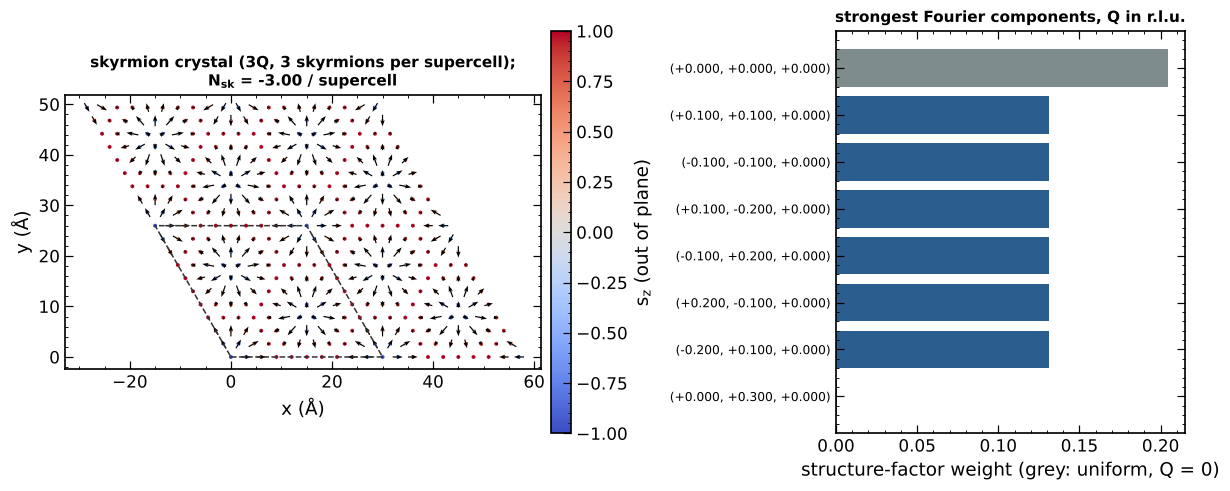

In [9]:
r14 = skx(14, size="auto")
report(r14, ["Mn"])
plot_state(r14);

The topological charge $N_{sk}=-3$ per 10×10 cell agrees with the geometry: $|Q|$ fixes a skyrmion lattice whose cell is 1/3 of the supercell.

### Field scan: cycloid → skyrmion crystal → ferromagnet

B =    0 T   E =  -4.69697 meV/cell   single-Q spiral
B =    4 T   E =  -4.71100 meV/cell   distorted single-Q spiral (harmonics 2q; weight 0.0036)
B =    8 T   E =  -4.78296 meV/cell   skyrmion crystal (3Q, 3 skyrmions per supercell)
B =   12 T   E =  -4.95663 meV/cell   skyrmion crystal (3Q, 3 skyrmions per supercell)
B =   16 T   E =  -5.16614 meV/cell   skyrmion crystal (3Q, 3 skyrmions per supercell)
B =   20 T   E =  -5.41256 meV/cell   skyrmion crystal (3Q, 3 skyrmions per supercell)
B =   24 T   E =  -5.77842 meV/cell   commensurate with the primitive cell (q = 0)
B =   28 T   E =  -6.24149 meV/cell   commensurate with the primitive cell (q = 0)


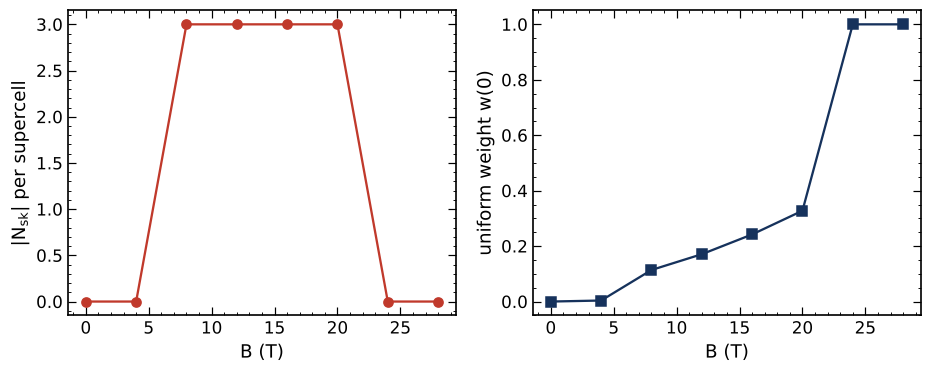

In [10]:
Bs = [0, 4, 8, 12, 16, 20, 24, 28]
scan = [skx(B) for B in Bs]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(Bs, [abs(r_["Q_top"]) for r_ in scan], "o-", color="#c0392b"); a1.set_xlabel("B (T)"); a1.set_ylabel("|N$_{sk}$| per supercell")
a2.plot(Bs, [r_["character"]["w0"] for r_ in scan], "s-", color="#16325c"); a2.set_xlabel("B (T)"); a2.set_ylabel("uniform weight w(0)")
for B, r_ in zip(Bs, scan):
    print(f"B = {B:4.0f} T   E = {r_['E_cell']:9.5f} meV/cell   {r_['character']['cls']}")

Near the upper boundary a 10×10 cell may show a state with fewer skyrmions — a **finite-cell effect**. Always compare the energy
per cell in other sizes before claiming a new phase (step 6 of the guide).

### Competing states and stability

In [11]:
for s_ in r14["seeds"][::8]:
    print(f"{s_['E_cell']:10.5f} meV/cell   {s_['seed']}")
r14s = skx(14, spectrum=True, n_per=8, nmap=5)
print("\nspin waves:", "UNSTABLE" if r14s["lswt"]["unstable"] else "stable", "; bands:", r14s["lswt"]["omega"].shape[1])

  -5.05682 meV/cell   multi-Q (3Q) + 0.4·n̂
  -5.05682 meV/cell   multi-Q (3Q), random phases + 0.4·n̂
  -4.99429 meV/cell   random 1
  -4.86710 meV/cell   conical q3, m∥ = 0.3
  -4.62075 meV/cell   conical q2, m∥ = 0.3



spin waves: stable ; bands: 100


## 6. Files for DFT and the symmetry of the new state

`write_outputs` (CLI: automatic, folder `supercell/`) writes `POSCAR`, a non-collinear `INCAR` (MAGMOM of the ground state),
`J_super.dat`, `spins.dat`, `seeds.dat`. The supercell state can then go through the full symmetry analysis:

In [12]:
import tempfile
from symphase import analyze_tensors
out = write_outputs(r14, ["Mn"], np.array([[0, 0, 2.0]]), tempfile.mkdtemp())
print(sorted(os.listdir(out)))
t = analyze_tensors(out, tensors="charge", quiet=True)
mg = t["magnetic"]
print("magnetic space group:", mg["bns_symbol"], "(BNS", mg["bns_number"] + ")  MPG", mg["magnetic_point_group"],
      "  T:", mg["time_reversal"], "  PT:", mg["PT"])

['INCAR', 'J_super.dat', 'POSCAR', 'seeds.dat', 'spins.dat']


magnetic space group: P6m'm' (BNS 183.189)  MPG 6m'm'   T: False   PT: False


The T-odd antisymmetric conductivity (σ_xy, the Hall response of the skyrmion crystal) is symmetry-allowed in P6m'm'.

## 7. Command line

```bash
cd examples/vasp/Conical_J1J2_field  && symphase magnons --J -1.0 0.5 --rmax 6.1 --spin 1 --field 0 0 2 --supercell auto
cd examples/vasp/Distorted_spiral_K  && symphase magnons --J -1.0 0.5 --rmax 6.1 --spin 1 --K 0.4 --K-axis 1 0 0 --scan 4 13 --supercell auto
cd examples/vasp/Skyrmion_triangular && symphase magnons --exchange J_DMI.dat --rmax 3.1 --spin 1 --field 0 0 14 --supercell auto
symphase tensors -p supercell/POSCAR -i supercell/INCAR
symphase magnons ... --supercell 7 1 1          # fixed size;  --supercell 2 1 0 -1 1 0 0 0 1  (matrix)
symphase magnons ... --restarts 30 --max-cells 600
```
Continue with **13_quiz_magnetic_supercells.ipynb**.